# 07. Live nowcast: Q3 and Q4 2026

Made with data published by the end of October 2026, before ONS's first estimate for Q3 2026
(due 12 November 2026). Intervals are empirical 80% intervals from each model's past
out-of-sample errors at the same horizon.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from nowcast.config import HORIZON_LABELS

In [2]:
live = pd.read_csv(T / "live_nowcast.csv")
for q in sorted(live.quarter.unique()):
    d = live[live.quarter == q].set_index("model")[["h", "nowcast", "lower80", "upper80"]]
    print(f"{q} (horizon {d.h.iloc[0]}: {HORIZON_LABELS[int(d.h.iloc[0])]})")
    display(d.drop(columns="h").round(2))

2026Q3 (horizon 3: Month after quarter)


,nowcast,lower80,upper80
model,,,
Mean,0.37,-0.15,0.72
AR,0.44,-0.23,0.79
Bridge,0.65,0.19,0.90
OLS (all),0.26,-0.36,0.61
Ridge,0.29,-0.30,0.62
Lasso,0.44,-0.12,0.70
Elastic net,0.45,-0.22,0.87
Adaptive lasso,0.47,-0.31,0.92
Group lasso,0.53,0.01,0.83


2026Q4 (horizon 0: End of month 1)


,nowcast,lower80,upper80
model,,,
Mean,0.37,-0.05,0.69
AR,0.37,-0.03,0.68
Bridge,0.49,0.04,0.74
OLS (all),0.33,-0.44,0.87
Ridge,0.40,-0.07,0.69
Lasso,0.30,-0.25,0.56
Elastic net,0.23,-0.24,0.52
Adaptive lasso,0.04,-0.49,0.35
Group lasso,0.10,-0.33,0.34


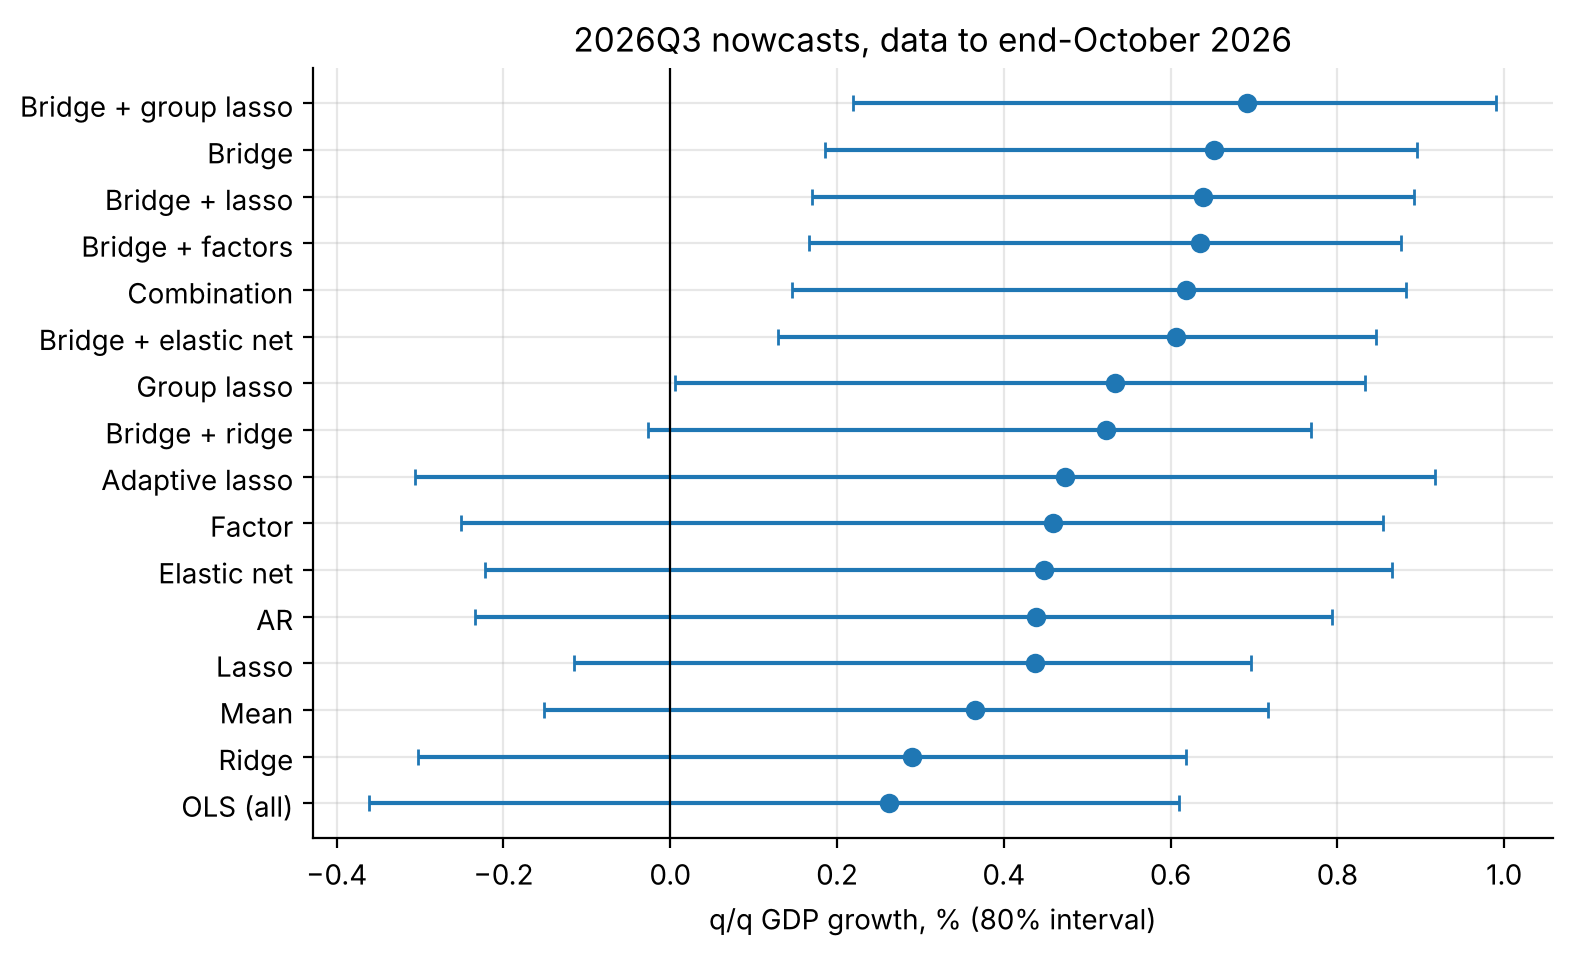

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
d = live[(live.quarter == "2026Q3")].set_index("model").sort_values("nowcast")
ax.errorbar(d.nowcast, range(len(d)), xerr=[d.nowcast - d.lower80, d.upper80 - d.nowcast],
            fmt="o", capsize=3)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
ax.axvline(0, c="k", lw=0.8); ax.set_xlabel("q/q GDP growth, % (80% interval)")
ax.set_title("2026Q3 nowcasts, data to end-October 2026");

**After 12 November 2026**: rerun `python scripts/run_pipeline.py --data` to download the new GDP
vintage; the 2026Q3 first estimate then appears in `data/processed/gdp_first_latest.csv` and can be
compared with the nowcast recorded here (the nowcast files are versioned in git).